# Deep Neural Network Assisted Optimization

**Contact:** Buxin She ([shebuxin@gmail.com](mailto:shebuxin@gmail.com))  

This notebook demonstrates how a trained deep neural network (DNN) can be embedded into an optimization model. We first train a small ReLU network to approximate a nonlinear constraint, then reformulate the trained network as mixed-integer linear programming (MILP) constraints and solve the resulting optimization problem.

## Table of Contents

0. [Setup](#step-0-setup)
1. [Problem Statement](#step-1-problem-statement)
2. [Generate Training Data](#step-2-generate-training-data)
3. [Train a Neural Network Surrogate](#step-3-train-a-neural-network-surrogate)
4. [Extract Network Parameters](#step-4-extract-network-parameters)
5. [Compute ReLU Bounds](#step-5-compute-relu-bounds)
6. [Build and Solve the MILP](#step-6-build-and-solve-the-milp)
7. [Visualize and Validate the Result](#step-7-visualize-and-validate-the-result)
8. [Advanced Application in Power System](#step-8-advanced-application-in-power-system)


## Step 0. Setup

We import the numerical, neural-network, and optimization packages used in this notebook. PuLP is used to build and solve the MILP formulation.


In [ ]:
# Step 0. Setup environment
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

!pip install pulp
from pulp import LpMaximize, LpProblem, LpVariable, LpBinary, lpDot, LpStatus, value

np.random.seed(42)
torch.manual_seed(42)

## Step 1. Problem Statement

We consider a simple optimization problem with a nonlinear feasibility constraint:

$$
\begin{aligned}
\max_{x_1, x_2} \quad & x_1 + x_2 \\
\text{s.t.} \quad & x_1^2 + x_2^2 \leq 1 \\
& -1.5 \leq x_1 \leq 1.5 \\
& -1.5 \leq x_2 \leq 1.5.
\end{aligned}
$$

The goal is not to solve this small problem in the easiest possible way. Instead, we use it as a controlled example to show the structure of DNN-assisted optimization.

### Workflow

1. Train a small ReLU network to approximate

   $$
   g(x) = x_1^2 + x_2^2 - 1,
   $$

   where $g(x) \leq 0$ means that the point is feasible.
2. Encode the trained ReLU network exactly as a piecewise-linear MILP model.
3. Solve the optimization problem using the network output $\hat{g}(x) \leq 0$ as a surrogate feasibility constraint.
4. Compare the MILP solution with the true nonlinear constraint.


## Step 2. Generate Training Data

We sample points from a box around the feasible region and compute the true nonlinear constraint value. These samples are used to train the surrogate model.


In [2]:
# --------------------------
# Step 2. Generate training data
# --------------------------

N = 6000
BOX_LB, BOX_UB = -1.5, 1.5

X = np.random.uniform(BOX_LB, BOX_UB, size=(N, 2)).astype(np.float32)
y = (X[:, 0]**2 + X[:, 1]**2 - 1.0).astype(np.float32).reshape(-1, 1)

X_t = torch.from_numpy(X)
y_t = torch.from_numpy(y)

## Step 3. Train a Neural Network Surrogate

We train a small feedforward ReLU network to approximate the nonlinear function $g(x)$. ReLU activations are useful here because they can later be represented by linear constraints and binary variables.


In [3]:
# ----------------------------------
# Step 3. Define and train a neural network
# ----------------------------------
class ReLURegressor(nn.Module):
    def __init__(self, in_dim=2, hidden=16, out_dim=1):
        super().__init__()
        self.fc1 = nn.Linear(in_dim, hidden)
        self.act = nn.ReLU()
        self.fc2 = nn.Linear(hidden, out_dim)
    def forward(self, x):
        return self.fc2(self.act(self.fc1(x)))

net = ReLURegressor(hidden=8)
optimizer = optim.Adam(net.parameters(), lr=1e-2)
loss_fn = nn.MSELoss()

net.train()
for epoch in range(400):
    optimizer.zero_grad()
    pred = net(X_t)
    loss = loss_fn(pred, y_t)
    loss.backward()
    optimizer.step()

# Quick train quality check
net.eval()
with torch.no_grad():
    mse = loss_fn(net(X_t), y_t).item()
print(f"[Train] Surrogate MSE: {mse:.4e}")

[Train] Surrogate MSE: 2.9611e-02


## Step 4. Extract Network Parameters

After training, we extract the weights and biases from the neural network. For a one-hidden-layer ReLU network, the surrogate has the form

$$
\hat{g}(x) = W_2 \max(W_1x + b_1, 0) + b_2.
$$


In [4]:
# ------------------------------------
# Step 4. Extract weights for MILP encoding
#    y_hat = W2 * ReLU(W1 x + b1) + b2
# ------------------------------------

W1 = net.fc1.weight.detach().numpy()  # shape (H, 2)
b1 = net.fc1.bias.detach().numpy()    # shape (H,)
W2 = net.fc2.weight.detach().numpy()  # shape (1, H)
b2 = net.fc2.bias.detach().numpy()    # shape (1,)

H = W1.shape[0]  # hidden size

## Step 5. Compute ReLU Bounds

To formulate each ReLU neuron with a tight big-M model, we need lower and upper bounds on each pre-activation value. Here we compute these bounds using interval arithmetic over the input box.


In [5]:
# ---------------------------------------------------------
# Step 5. Tight bounds for pre-activations (interval arithmetic)
#    Given x in [lb_x, ub_x], for a_i = W1[i,:] @ x + b1[i],
#    L1[i] = min_x a_i(x), U1[i] = max_x a_i(x).
# ---------------------------------------------------------

lb_x = np.array([BOX_LB, BOX_LB], dtype=np.float64)
ub_x = np.array([BOX_UB, BOX_UB], dtype=np.float64)

def linear_bounds(W_row, b, lb, ub):
    """
    Compute min and max of W_row @ x + b over lb <= x <= ub (box).
    """
    assert W_row.shape == lb.shape == ub.shape
    lo = b
    hi = b
    for j, w in enumerate(W_row):
        if w >= 0:
            lo += w * lb[j]
            hi += w * ub[j]
        else:
            lo += w * ub[j]
            hi += w * lb[j]
    return lo, hi

L1 = np.zeros(H)
U1 = np.zeros(H)

for i in range(H):
    L1[i], U1[i] = linear_bounds(W1[i, :], b1[i], lb_x, ub_x)
    # Ensure we have both negative and positive potential to enable a proper ReLU split.
    # If interval does not cross zero, ReLU is trivially linear (no binary needed).
    # We'll still handle both cases with a unified formulation.
    if L1[i] > U1[i]:
        L1[i], U1[i] = U1[i], L1[i]

## Step 6. Build and Solve the MILP

The trained ReLU network is embedded into an MILP. For each hidden neuron, we introduce:

- $a_i$: pre-activation value;
- $z_i$: post-activation value;
- $\delta_i$: binary variable indicating whether the ReLU is active.

The MILP maximizes $x_1 + x_2$ while enforcing the surrogate constraint $\hat{g}(x) \leq 0$.


In [6]:
# --------------------------
# Step 6. Build MILP
#    Variables:
#      x in [BOX_LB, BOX_UB]^2 (continuous)
#      For each hidden neuron i:
#         a_i (pre-activation), z_i (post-activation), δ_i (binary: active/inactive)
#
#    ReLU big-M (tightened with L1[i], U1[i]):
#       a_i = W1[i,:] x + b1[i]
#       z_i >= a_i
#       z_i >= 0
#       z_i <= a_i - L1[i]*(1 - δ_i)
#       z_i <= U1[i]*δ_i
#
#    Output:
#       y_hat = W2 z + b2  and enforce y_hat <= 0
# --------------------------

prob = LpProblem("NN_constrained_optimization", LpMaximize)

# Decision variables x
x1 = LpVariable("x1", lowBound=BOX_LB, upBound=BOX_UB)
x2 = LpVariable("x2", lowBound=BOX_LB, upBound=BOX_UB)

# Pre/post-activation & binaries
a = [LpVariable(f"a_{i}", lowBound=L1[i], upBound=U1[i]) for i in range(H)]
z = [LpVariable(f"z_{i}", lowBound=0) for i in range(H)]   # ReLU output >= 0
delta = [LpVariable(f"delta_{i}", cat=LpBinary) for i in range(H)]

# Objective: maximize x1 + x2
prob += x1 + x2, "maximize_sum"

# Preactivation definitions and ReLU big-M constraints
for i in range(H):
    # a_i = W1[i,0]*x1 + W1[i,1]*x2 + b1[i]
    prob += a[i] == W1[i, 0] * x1 + W1[i, 1] * x2 + float(b1[i])

    # Standard tight big-M for ReLU with known bounds [L1[i], U1[i]]
    # z_i >= a_i
    prob += z[i] - a[i] >= 0
    # z_i >= 0  -> already via lowBound=0 (kept for clarity)
    # z_i <= a_i - L1[i]*(1 - δ_i)
    prob += z[i] - a[i] <= -L1[i] * (1 - delta[i])
    # z_i <= U1[i]*δ_i
    prob += z[i] <= U1[i] * delta[i]

# Output & constraint y_hat <= 0
# y_hat = W2 @ z + b2
y_hat = lpDot(list(W2[0, :]), z) + float(b2[0])
prob += y_hat <= 0.0, "surrogate_constraint"

# Solve MILP
status = prob.solve()  # CBC by default with PuLP
print(f"\nMILP status: {LpStatus[status]}")

x1_sol = value(x1)
x2_sol = value(x2)
yhat_sol = value(y_hat)

print(f"Solution x*: ({x1_sol:.4f}, {x2_sol:.4f})")
print(f"Objective value x1+x2: {x1_sol + x2_sol:.4f}")
print(f"Surrogate y_hat(x*): {yhat_sol:.6f}  (<= 0 means net predicts feasible)")

# True nonlinear check:
true_g = x1_sol**2 + x2_sol**2 - 1.0
print(f"True g(x*) = x1^2 + x2^2 - 1: {true_g:.6f}  (<= 0 means truly feasible)")


Welcome to the CBC MILP Solver 
Version: 2.10.13 
Build Date: May 12 2026 

command line - cbc /var/folders/28/gzpwkhgj5wl3tstf1wy9p_1r0000gn/T/e22df6d2ed834aa4bb3c2686cf9518ad-pulp.mps -max -timeMode elapsed -branch -printingOptions all -solution /var/folders/28/gzpwkhgj5wl3tstf1wy9p_1r0000gn/T/e22df6d2ed834aa4bb3c2686cf9518ad-pulp.sol (default strategy 1)
At line 2 NAME          MODEL
At line 3 ROWS
At line 38 COLUMNS
At line 145 RHS
At line 179 BOUNDS
At line 208 ENDATA
Problem MODEL has 33 rows, 26 columns and 88 elements
Coin0008I MODEL read with 0 errors
Option for timeMode changed from cpu to elapsed
Continuous objective value is 1.32056 - 0.00 seconds
Cgl0003I 0 fixed, 0 tightened bounds, 4 strengthened rows, 0 substitutions
Cgl0003I 0 fixed, 0 tightened bounds, 5 strengthened rows, 0 substitutions
Cgl0003I 0 fixed, 0 tightened bounds, 3 strengthened rows, 0 substitutions
Cgl0003I 0 fixed, 0 tightened bounds, 3 strengthened rows, 0 substitutions
Cgl0003I 0 fixed, 0 tightened bo

## Step 7. Visualize and Validate the Result

Finally, we compare the NN-assisted MILP solution with the true circular constraint and the theoretical optimum. This check is important because the optimizer only sees the surrogate constraint.


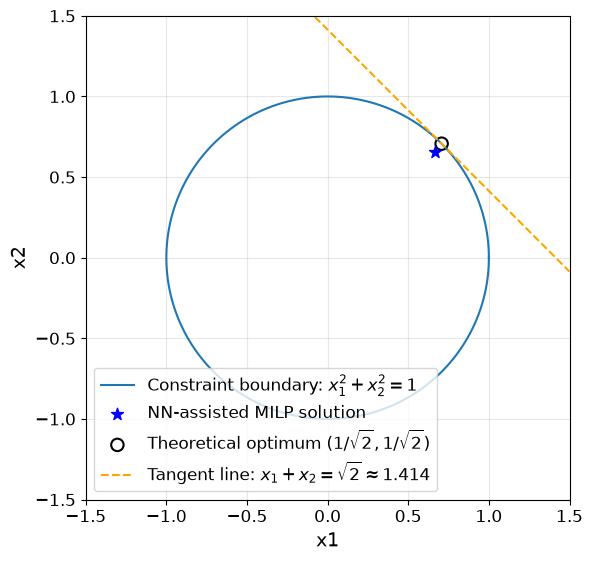

In [7]:
# --------------------------
# Step 7. Visualization
# --------------------------
try:
    import matplotlib.pyplot as plt

    # Unit circle boundary
    theta = np.linspace(0, 2*np.pi, 400)
    xs = np.cos(theta)
    ys = np.sin(theta)

    # Theoretical optimum and tangent line
    sqrt2 = float(np.sqrt(2.0))
    x_th = 1.0 / sqrt2
    theo_point = (x_th, x_th)  # (1/√2, 1/√2)
    # Tangent line: x1 + x2 = √2  => y = √2 - x
    grid = np.linspace(BOX_LB, BOX_UB, 400)
    y_line = sqrt2 - grid
    mask = (y_line >= BOX_LB) & (y_line <= BOX_UB)

    fig, ax = plt.subplots(figsize=(6, 6))

    # Plot constraint boundary
    ax.plot(xs, ys, label=r"Constraint boundary: $x_1^2 + x_2^2 = 1$", linewidth=1.5)

    # Plot NN-assisted MILP solution
    ax.scatter([x1_sol], [x2_sol], s=80, marker="*",
               color="blue", label="NN-assisted MILP solution", zorder=5)

    # Plot theoretical optimum (raw string for LaTeX math)
    ax.scatter([theo_point[0]], [theo_point[1]], s=80, marker="o",
               facecolors="none", edgecolors="k", linewidths=1.5,
               label=r"Theoretical optimum $(1/\sqrt{2}, 1/\sqrt{2})$")

    # Plot tangent line
    ax.plot(grid[mask], y_line[mask], linestyle="--", color="orange",
            linewidth=1.5, label=fr"Tangent line: $x_1 + x_2 = \sqrt{{2}} \approx {sqrt2:.3f}$")

    # Style and fonts
    ax.set_xlim(BOX_LB, BOX_UB)
    ax.set_ylim(BOX_LB, BOX_UB)
    ax.set_aspect("equal", "box")
    ax.grid(True, alpha=0.3)

    # Increase font sizes
    ax.set_xlabel("x1", fontsize=14)
    ax.set_ylabel("x2", fontsize=14)
    ax.tick_params(axis="both", labelsize=12)
    ax.legend(fontsize=12, loc="lower left")

    fig.tight_layout()
    plt.show()

except Exception as e:
    print("(Plot skipped) Matplotlib issue:", e)


## Step 8. Advanced Application in Power System

The example above demonstrates a basic workflow for deep neural network (DNN)-assisted optimization: approximate a nonlinear constraint with a ReLU network and embed it in a mixed-integer linear programming (MILP) model.

In power systems, this idea is useful when security constraints are nonlinear, dynamic, or expensive to model directly. The two papers below apply this concept to virtual inertia scheduling (VIS), where inverter-based resources (IBRs) are scheduled to provide frequency support while satisfying economic and security requirements.

- [Virtual Inertia Scheduling (VIS) for Real-Time Economic Dispatch of IBR-Penetrated Power Systems](https://ieeexplore.ieee.org/abstract/document/10264213)
- [Virtual Inertia Scheduling (VIS) for Microgrids With Static and Dynamic Security Constraints](https://ieeexplore.ieee.org/document/10729702/)

As you read, focus on:

1. Which constraints are approximated or linearized?
2. How are feasibility and dynamic security verified?
